# 06 · Tools that work: names, schemas and errors the model can act on
Level L2 · Part 2 · core · ~25 min · builds on 05

## Goal
Turn ordinary Python functions into tools the model uses correctly, and make a tool error something the model can recover from,
inside an agent graph. The description, the argument schema and the error text are the three things the model reads.

## Why it matters
A model chooses a tool from its name and description, and fills its arguments from the schema. A vague description makes it pick the
wrong tool. A bad argument that fails with a stack trace teaches the model nothing, so it either repeats the mistake or gives up.

| Without care | With care |
|---|---|
| A tool named `do_thing` with no description | A name and a docstring that say when to use it |
| An error that says "KeyError: '1093'" | An error that names the field and the next step |
| The model guesses the argument format | The schema says "four digits, such as 1093" |

**What it makes easy:** a model that recovers from a bad call on its own. **When you don't need it:** a tool you call from code
yourself, with no model in between.

## The idea
A **tool** is a function plus three things the model reads: its **name**, its **description** (the docstring) and its **argument
schema** (typed fields with descriptions). When the model asks for a tool, the graph checks the arguments against the schema. A
failed check becomes a **tool message** with the error text, and the model reads it and tries again.

## Picture
The loop from lesson 05, with one change: a failed tool call goes back to the model as a message, not as a crash.
`graph_view` is a course helper that draws graphs; `show_mermaid` draws a diagram written as Mermaid text.

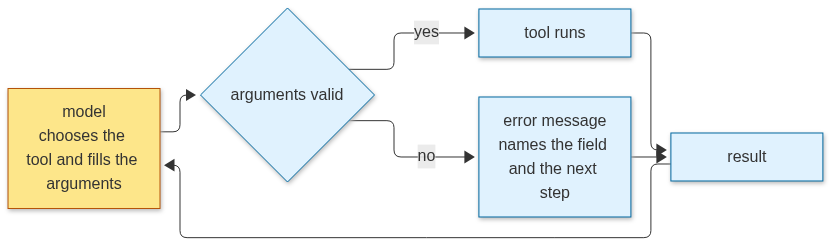

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  M["model<br/>chooses the tool and fills the arguments"] --> Q{"arguments valid"}
  Q -->|yes| T["tool runs"]
  Q -->|no| E["error message<br/>names the field and the next step"]
  T --> R["result"]
  E --> R
  R --> M
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  class M model
  class Q,T,E,R code
""")

## Step by step

**Step 1 · the tools (no call).** Two tools for the support desk. Each has a short name, a docstring that says when to use it, and
an argument schema with a description for each field. The order number is a string of four digits, and the schema says so.

In [2]:
from langchain_core.tools import tool
from pydantic import BaseModel, ConfigDict, Field

ORDERS = {"1093": {"status": "in transit", "days_late": 3}, "2207": {"status": "delivered", "days_late": 0}}


class OrderQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")  # a field the schema does not name is refused
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 1093.",
                          pattern=r"^\d{4}$")


@tool(args_schema=OrderQuery)
def lookup_order(order_id: str) -> dict:
    """Look up one customer order: its status and days late. Use it when the customer gives an order number."""
    if order_id not in ORDERS:  # the error names the next step, so the model can recover
        return {"error": f"no order {order_id}", "next_step": "Ask the customer for the number in the confirmation email."}
    return ORDERS[order_id]


print(lookup_order.name, "|", lookup_order.description)
print("schema the model sees:", list(lookup_order.args_schema.model_json_schema()["properties"]))

lookup_order | Look up one customer order: its status and days late. Use it when the customer gives an order number.
schema the model sees: ['order_id']


**Step 2 · two ways a call goes wrong (no model call).** Path A and Path B below are labelled in the output.
**Path A:** the call is valid, the tool runs, and it returns an error as its normal result. No exception is raised: the dict is the
result the model reads.

In [3]:
print("Path A · the tool returns an error as a normal result:")
print(lookup_order.invoke({"order_id": "9999"}))

Path A · the tool returns an error as a normal result:
{'error': 'no order 9999', 'next_step': 'Ask the customer for the number in the confirmation email.'}


**Path B:** a schema refusal. The argument `"12"` is not four digits, so the check fails before the function runs. Called directly,
the tool raises an exception. The cell catches it and prints only the exception name and the first line of its message.

In [4]:
print("Path B · schema refusal, '12' is not four digits:")
try:
    lookup_order.invoke({"order_id": "12"})
except Exception as err:  # the schema refused the call, so the tool body never ran
    print(type(err).__name__, "|", str(err).splitlines()[0])

Path B · schema refusal, '12' is not four digits:
ValidationError | 1 validation error for OrderQuery


Path B inside the graph. The customer's call has an extra field, `days`, which `extra="forbid"` refuses. The imports the graph needs
come first, with a note on each: `AIMessage` is a model reply that asks for a tool, `ToolNode` runs the requested tools,
`StateGraph` builds a graph, `START` and `END` mark its entry and exit, and `MessagesState` is the list of messages a graph passes
between its steps. `handle_tool_errors=True` turns the refusal into a tool message the model can read.

In [5]:
from langchain_core.messages import AIMessage  # a model reply that asks for one tool call
from langgraph.graph import END, START, MessagesState, StateGraph  # graph builder, entry and exit markers, the message-list state
from langgraph.prebuilt import ToolNode  # runs the tool calls in a reply and turns their errors into messages

bad_call = AIMessage(content="", tool_calls=[{"name": "lookup_order", "args": {"order_id": "1093", "days": 9}, "id": "c1"}])
tool_only = (StateGraph(MessagesState)  # a one-node graph that holds only the tools node
             .add_node("tools", ToolNode([lookup_order], handle_tool_errors=True))
             .add_edge(START, "tools").add_edge("tools", END).compile())
reply = tool_only.invoke({"messages": [bad_call]})
print("Path B · first line of the message back to the model:", reply["messages"][-1].content.splitlines()[0])

Path B · first line of the message back to the model: Error: ToolInvocationError("Error invoking tool 'lookup_order' with kwargs {'order_id': '1093', 'days': 9} with error:\n days: Extra inputs are not permitted\n Please fix the error and try again.")


**Step 3 · the agent with these tools (2 model calls).** The model is given the tools and a customer message. Its first reply asks for
`lookup_order`; the `ToolNode` runs it and the model writes the answer. The loop is the one from lesson 05, drawn as a graph.
`llm_replay` is a course helper that records the model's answers on the first run and replays them afterwards, so this step runs
offline with no key. `get_llm` is the course helper that returns the course's model. `recursion_limit` (set in the run below) is the
most graph steps one run may take; 8 stops a model that keeps calling tools instead of looping forever.

In [6]:
import llm_replay  # course helper: records and replays model calls (not part of LangGraph)
llm_replay.start("06_tools-that-work")

from langchain_core.messages import HumanMessage  # the customer's message
from langgraph.graph import END, START, MessagesState, StateGraph  # graph builder, entry and exit markers, the message-list state
from langgraph.prebuilt import ToolNode, tools_condition  # ToolNode runs the tools; tools_condition sends a tool-asking reply to "tools", else to END
from llm_setup import get_llm  # course helper: the shared model setup (Gemini on Vertex AI)
from graph_view import show_graph  # course helper: draws the compiled graph

llm = get_llm()
model = llm.bind_tools([lookup_order])  # bind_tools tells the model which tools it may call


def call_model(state: MessagesState) -> dict:
    return {"messages": [model.invoke(state["messages"])]}

LLM mode: replay (06_tools-that-work.yaml)


Gemini on Vertex AI · API key loaded: True


Next, wire the graph: a `model` node, a `tools` node, and an edge back from the tools to the model. The conditional edge is the
routing rule: `tools_condition` looks at the model's reply and picks "tools" when it asks for a tool, or END when it has an answer.

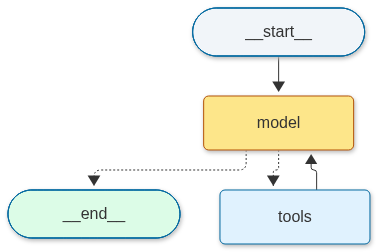

In [7]:
g = StateGraph(MessagesState)
g.add_node("model", call_model)
g.add_node("tools", ToolNode([lookup_order], handle_tool_errors=True))
g.add_edge(START, "model")
g.add_conditional_edges("model", tools_condition, {"tools": "tools", END: END})
g.add_edge("tools", "model")
desk = g.compile()
show_graph(desk, model_nodes=("model",))

Run it on one customer question. The printout shows each tool request, the tool's result, and the model's final answer. The
`recursion_limit` setting caps the run as described above.

In [8]:
result = desk.invoke({"messages": [HumanMessage(content="Where is order 1093? Tell me its status in one sentence.")]},
                     config={"recursion_limit": 8})  # the most graph steps one run may take
for m in result["messages"][1:]:
    for call in getattr(m, "tool_calls", []) or []:
        print("the model asks for:", call["name"], call["args"])
    if m.type == "tool":
        print("the tool returns:", m.content)
print("answer:", result["messages"][-1].text)
llm_replay.stop()  # the last model call of this lesson

the model asks for: lookup_order {'order_id': '1093'}
the tool returns: {"status": "in transit", "days_late": 3}
answer: Order 1093 is currently in transit and is 3 days late.


## At work
- Teams write the description as a contract: when to use the tool, and when not to. A tool with a clear description is picked
  correctly more often, and its eval scores show it → lesson 07 (evals and safety).
- A tool error is data for the model. Teams return the reason and the next step, never a stack trace → lesson 35 (reliability).
- The argument schema is the first check on what the model sends. It runs before any side effect → lesson 26 (guardrails).

## What just happened
- Path A printed an error dict as a normal result, with the field `next_step`; nothing was raised.
- Path B refused `"12"` before the tool ran: the first line names `OrderQuery`, the schema that refused it. The graph version
  returned the refusal as a tool message, and the message names the extra field `days`.
- The agent made 2 model calls: one asked for `lookup_order` with order `1093`, the tool returned `in transit`, 3 days late, and the
  model wrote the answer.

## Common mistakes
1. **A vague name and no docstring.** The model chooses from these. `do_thing` tells it nothing; `lookup_order` tells it what to use.
2. **An error the model cannot act on.** "Failed" is not an instruction. Path A names the field and the next step; a bare "failed"
   would leave the model guessing.
3. **An argument the schema does not name.** The schema refuses it, so the tool never runs. Path B shows the refusal, with `days`
   as the extra field.

## Try it
Write an order-status tool. Create a schema `StatusQuery` with one field `order_id` (four digits, with a pattern and a
description, and `extra="forbid"`), and a tool `order_status` with that schema that returns the order's entry from `ORDERS`.
Then call it with `"12"` inside `try`/`except`, print the exception name and the first line of its message, and say in one
sentence what the model should do after reading that line.

In [9]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [10]:
class StatusQuery(BaseModel):
    model_config = ConfigDict(extra="forbid")
    order_id: str = Field(description="The order number the customer wrote: four digits, such as 2207.", pattern=r"^\d{4}$")


@tool(args_schema=StatusQuery)
def order_status(order_id: str) -> dict:
    """Return the delivery status of one order. Use it when the customer gives an order number."""
    return ORDERS[order_id]


print("ok:", order_status.invoke({"order_id": "2207"}))
try:
    order_status.invoke({"order_id": "12"})
except Exception as err:
    print(type(err).__name__, "|", str(err).splitlines()[0])

ok: {'status': 'delivered', 'days_late': 0}
ValidationError | 1 validation error for StatusQuery


## Key terms
- **Tool** — a function plus a name, a description and an argument schema, which the model can ask to run.
- **Argument schema** — the typed fields a tool accepts; the graph checks the model's arguments against it before the tool runs.
- **Schema refusal** — the error raised when arguments fail the schema; the tool body never runs.
- **Tool message** — the message that carries a tool's result, or its error, back to the model.
- **`ToolNode`** — the LangGraph node that runs the tool calls in a model reply.
- **`handle_tool_errors`** — the `ToolNode` option that turns a tool error into a tool message instead of a crash.
- **`bind_tools`** — attaches the tool list to a model so it knows which tools it may request.
- **`recursion_limit`** — the maximum number of graph steps one run may take; it stops a loop that never ends.

## Recap
- A tool is a function with a name, a description and an argument schema. The model reads all three.
- The schema refuses a bad argument before the tool runs, and the error goes back to the model as a message.
- A good error names the field and the next step, so the model can recover without a person.

**Interview:** "The model keeps calling your tool with the wrong arguments. What do you change?" Strong answer: "I check the tool's
name, description and schema first, because the model reads those. Then I make the error name the field and the next step, and
I set a step limit (`recursion_limit`, Step 3) so a stuck loop stops."